<a href="https://colab.research.google.com/github/Mukundan-T/seqADAGE/blob/main/Py/muk_uADAGE/L2OnlyEcoliModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# L2-Only Regularized E. coli Models

### By: Mukundan Thanigaivelan

### October 13, 2026

In this notebook, we will be training E. coli models with the standard ADAGE loss function (mean squared error) in addition to a **L2 regularizer** as experimental models.

## 0. Connect to GitHub

In [1]:
!git clone https://github.com/Mukundan-T/seqADAGE.git

Cloning into 'seqADAGE'...
remote: Enumerating objects: 1010, done.
remote: Counting objects: 100% (232/232), done.
remote: Compressing objects: 100% (161/161), done.
remote: Total 1010 (delta 177), reused 77 (delta 71), pack-reused 778 (from 2)
Receiving objects: 100% (1010/1010), 60.21 MiB | 6.68 MiB/s, done.
Resolving deltas: 100% (596/596), done.


In [2]:
%cd seqADAGE/Py/muk_uADAGE

/content/seqADAGE/Py/muk_uADAGE


In [3]:
!pip install -qq tensorflow keras statsmodels seaborn keras_tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 835.1 kB/s eta 0:00:00


## 1. Loading classes & modules

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

In [7]:
# ADAGE
from adage import Adage as ad, SeqAdage, LinkedAE

# Data Analysis
import pandas as pd
import numpy as np
import keras

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Miscellaneous
import zipfile
import time
import json
import tensorflow as tf
from types import SimpleNamespace

In [8]:
# check CPU and GPU available in runtime
print("Num CPUs Available: ", len(tf.config.list_physical_devices('CPU')))
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
print(tf.test.is_built_with_cuda())

Num CPUs Available:  1
Num GPUs Available:  1
True


## 2. L2 E. coli ADAGE

Hyperparameter search results:

* Units: 100
* Dropout: 0
* Activation 1: Sigmoid
* Activation 2: Sigmoid
* Shuffle: True
* Initialization: glorot_normal
* kl1: 0
* kl2: 0.7000000000000001
* lr: 0.07100000000000001
* bs: 25
* mm: 0.6000000000000001

### 2a. Find and save optimal model hyperparameters

In [9]:
# Load filtered and re-normalized data
filename = '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk.csv'

filtered_df = pd.read_csv(filename, index_col = 0)
filtered_df.shape

(3608, 10233)

In [ ]:
# Find optimal hyperparameter values
model_trainer = SeqAdage.SeqAdage(filename)
best_hps, tuner = model_trainer.tune_model(
  seed = 42,
  k1 = [0, 0, 0.1],
  d = [0, 0, 0.1]
)

Trial 90 Complete [00h 00m 47s]
val_loss: 0.06802328675985336

Best val_loss So Far: 0.012985623441636562
Total elapsed time: 00h 21m 22s
Results summary
Results in /content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk_42
Showing 10 best trials
Objective(name="val_loss", direction="min")

Trial 0072 summary
Hyperparameters:
units: 90
dropout: 0.0
act1: tanh
shuffle: False
init: glorot_uniform
kl1: 0.0
kl2: 0.0
lr: 0.061
bs: 20
mm: 0.0
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 2
tuner/round: 2
tuner/trial_id: 0067
Score: 0.012985623441636562

Trial 0067 summary
Hyperparameters:
units: 90
dropout: 0.0
act1: tanh
shuffle: False
init: glorot_uniform
kl1: 0.0
kl2: 0.0
lr: 0.061
bs: 20
mm: 0.0
tuner/epochs: 17
tuner/initial_epoch: 6
tuner/bracket: 2
tuner/round: 1
tuner/trial_id: 0059
Score: 0.013184820301830769

Trial 0059 summary
Hyperparameters:
units: 90
dropout: 0.0
act1: tanh
shuffle: False
init: glorot_uniform
kl1: 0.0
kl2: 0.0
lr: 

In [ ]:
# Optimal hyperparameters - decide based on nonzero l2 regularization value
hps = best_hps[6].values
hps

{'units': 100,
 'dropout': 0.0,
 'act1': 'sigmoid',
 'shuffle': True,
 'init': 'glorot_normal',
 'kl1': 0.0,
 'kl2': 0.7000000000000001,
 'lr': 0.07100000000000001,
 'bs': 25,
 'mm': 0.6000000000000001,
 'tuner/epochs': 50,
 'tuner/initial_epoch': 17,
 'tuner/bracket': 3,
 'tuner/round': 3,
 'tuner/trial_id': '0047'}

In [ ]:
# Save optimal model hyperparameters
hps['act1/act2'] = hps.pop('act1')
optimal_hps = {param: val for param, val in hps.items() if not param.startswith('tuner')}
with open('/content/drive/My Drive/Mukundan - Senior Project/L2 Models/ec_L2_model_hps.json', "w") as f:
  json.dump(optimal_hps, f)

### 2b. Train, choose, and save optimal models

In [ ]:
# Load hyperparameters
with open('/content/drive/My Drive/Mukundan - Senior Project/L2 Models/ec_L2_model_hps.json', 'r') as f:
  optimal_hps = json.load(f)

# Train models
l2_models = {}
ec_objs = []
seeds = list(range(75))

for seed in seeds:
  sa = SeqAdage.SeqAdage(
    filename,
    seed = seed + 100,
    enc_dim = optimal_hps['units'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    act = optimal_hps['act1/act2'],
    act2 = optimal_hps['act1/act2'],
    epochs = 50,
    init = optimal_hps['init'],
    batch_size = optimal_hps['bs'],
    dropout = optimal_hps['dropout'],
    mm = optimal_hps['mm'],
    lr = optimal_hps['lr']
  )
  sa.train_model()
  temp = ad.Adage(sa.autoencoder, sa.history, sa.all_comp)

  ec_objs.append(sa)
  l2_models[seed] = temp
  print(f'\nFinished {seed+1}/{len(seeds)}\n')

In [11]:
# Create enrichment dataframes
kegg_dfs = {}

for seed in l2_models.keys():
  ec_kegg_ps = l2_models[seed].set_kegg(
    '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ec_kegg_pathways.txt'
  )
  kegg_dfs[seed] = ec_kegg_ps

In [12]:
# Save sum of p-values and pathways to lists
p_val_sums = []
path_info = []

for df in kegg_dfs.values():
  p_val_sums.append(df.sum().sum())
  path_info.append(df.columns[(df > 1.5).any()].tolist())

In [13]:
# Inspect p-values
p_val_sums

[np.float64(2666.0918595945823),
 np.float64(6107.299562787847),
 np.float64(6016.757815545572),
 np.float64(9749.088093345606),
 np.float64(6240.564802813424),
 np.float64(9094.93138486723),
 np.float64(2568.798485065472),
 np.float64(8642.310209773314),
 np.float64(2864.9495522285533),
 np.float64(4918.856892178918),
 np.float64(2666.0918595945823),
 np.float64(6240.564802813424),
 np.float64(6467.19748208851),
 np.float64(5884.852688243742),
 np.float64(7787.978013812302),
 np.float64(2666.0918595945823),
 np.float64(6920.516922532389),
 np.float64(2170.1436876915313),
 np.float64(6248.011935812426),
 np.float64(5884.852688243742),
 np.float64(6467.19748208851),
 np.float64(6547.532990104614),
 np.float64(6693.18597790734),
 np.float64(4571.889094651421),
 np.float64(5067.837266554472),
 np.float64(6467.19748208851),
 np.float64(5350.550908671668),
 np.float64(2530.704634085848),
 np.float64(8101.206955978145),
 np.float64(3718.817150440768),
 np.float64(6710.006339575781),
 np.floa

In [14]:
# Save all best models
for seed in seeds:
  ec_objs[seed].autoencoder.save(
    f'/content/drive/My Drive/Mukundan - Senior Project/L2 Models/ec_best_model{seed+1}.keras'
  )

In [15]:
# Save training/validation loss history
for seed in seeds:
  for loss_type in ['loss', 'val_loss']:
    np.savetxt(
      f'/content/drive/My Drive/Mukundan - Senior Project/L2 Models/loss_history/ec_L2_{loss_type}_model{seed+1}.csv',
      ec_objs[seed].history.history[loss_type],
      delimiter=','
    )

In [16]:
# Save KEGG enrichment matrices for all best models
for seed in seeds:
  kegg_dfs[seed].to_csv(
    f'/content/drive/My Drive/Mukundan - Senior Project/L2 Models/kegg_dfs/ec_L2_kegg_ps{seed+1}.csv',
  )

### 2c. Load optimal models

In [20]:
model_filenames = [
  f'/content/drive/My Drive/Mukundan - Senior Project/L2 Models/ec_best_model{i+1}.keras'
  for i in range(10)
]

In [21]:
# Load hyperparameters
with open('/content/drive/My Drive/Mukundan - Senior Project/L2 Models/ec_L2_model_hps.json', 'r') as f:
  optimal_hps = json.load(f)

In [22]:
loaded_models = []

for i, file in enumerate(model_filenames):
  # Create autoencoder object
  ae = LinkedAE.LinkedAE(
    encoding_dim = optimal_hps['units'],
    act1 = optimal_hps['act1/act2'],
    d = optimal_hps['dropout'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    init = optimal_hps['init']
  )
  ae(tf.zeros((1, filtered_df.shape[0])))

  # Pull model weights
  with zipfile.ZipFile(file) as z:
    z.extract('model.weights.h5')

  # Load saved weights
  ae.load_weights('model.weights.h5')

  # Create ADAGE object
  adage = ad.Adage(
    autoencoder = ae,
    history = SimpleNamespace(
      history = {
        'loss': np.loadtxt(
                  f'/content/drive/My Drive/Mukundan - Senior Project/L2 Models/loss_history/ec_L2_loss_model{i+1}.csv',
                  delimiter=','
                ).reshape(-1).tolist(),
        'val_loss': np.loadtxt(
                      f'/content/drive/My Drive/Mukundan - Senior Project/L2 Models/loss_history/ec_L2_val_loss_model{i+1}.csv',
                      delimiter=','
                    ).reshape(-1).tolist()
      }
    ),
    train_comp = pd.read_csv(
      '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk.csv',
      index_col = 0
    )
  )

  # Add model to list
  loaded_models.append(adage)

### 2d. Loss curves and weight distributions

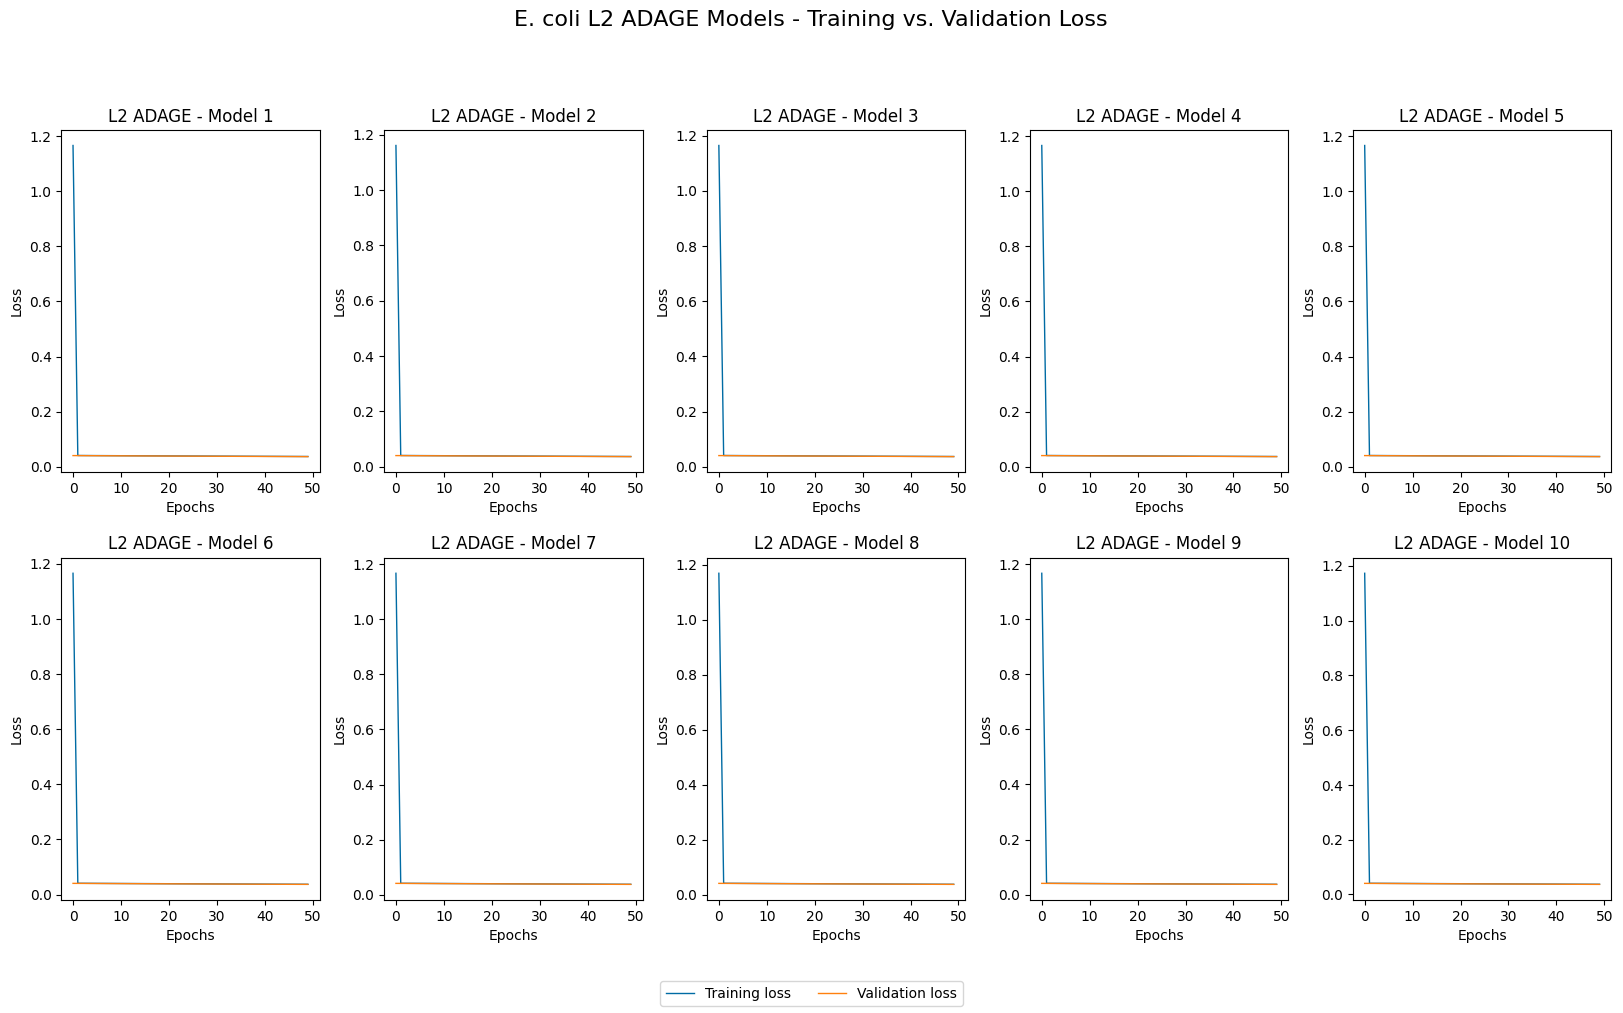

In [24]:
plot_titles = [
  f'L2 ADAGE - Model {i+1}'
  for i in range(10)
]
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots(2, 5, figsize = (20, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli L2 ADAGE Models - Training vs. Validation Loss',
  fontsize = 16,
  y = 1
)

# Only plot curves for first 10 models - rest will be similar
for i in range(2):
  for j in range(5):
    ax[i, j].plot(
      range(50),
      loaded_models[5*i + j].history.history['loss'],
      linewidth = 1,
      label = 'Training loss'
    )
    ax[i, j].plot(
      range(50),
      loaded_models[5*i + j].history.history['val_loss'],
      linewidth = 1,
      label = 'Validation loss'
    )
    ax[i, j].set(
      title = plot_titles[5*i + j],
      xlabel = 'Epochs',
      ylabel = 'Loss'
    )

handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(
  handles,
  labels,
  loc = 'lower center',
  ncol = 2,
  fontsize = 10
)

fig.savefig(
  '/content/drive/MyDrive/Mukundan - Senior Project/L2 Models/Plots/ec_l2_loss.png',
  dpi = 300,
  bbox_inches = 'tight'
)

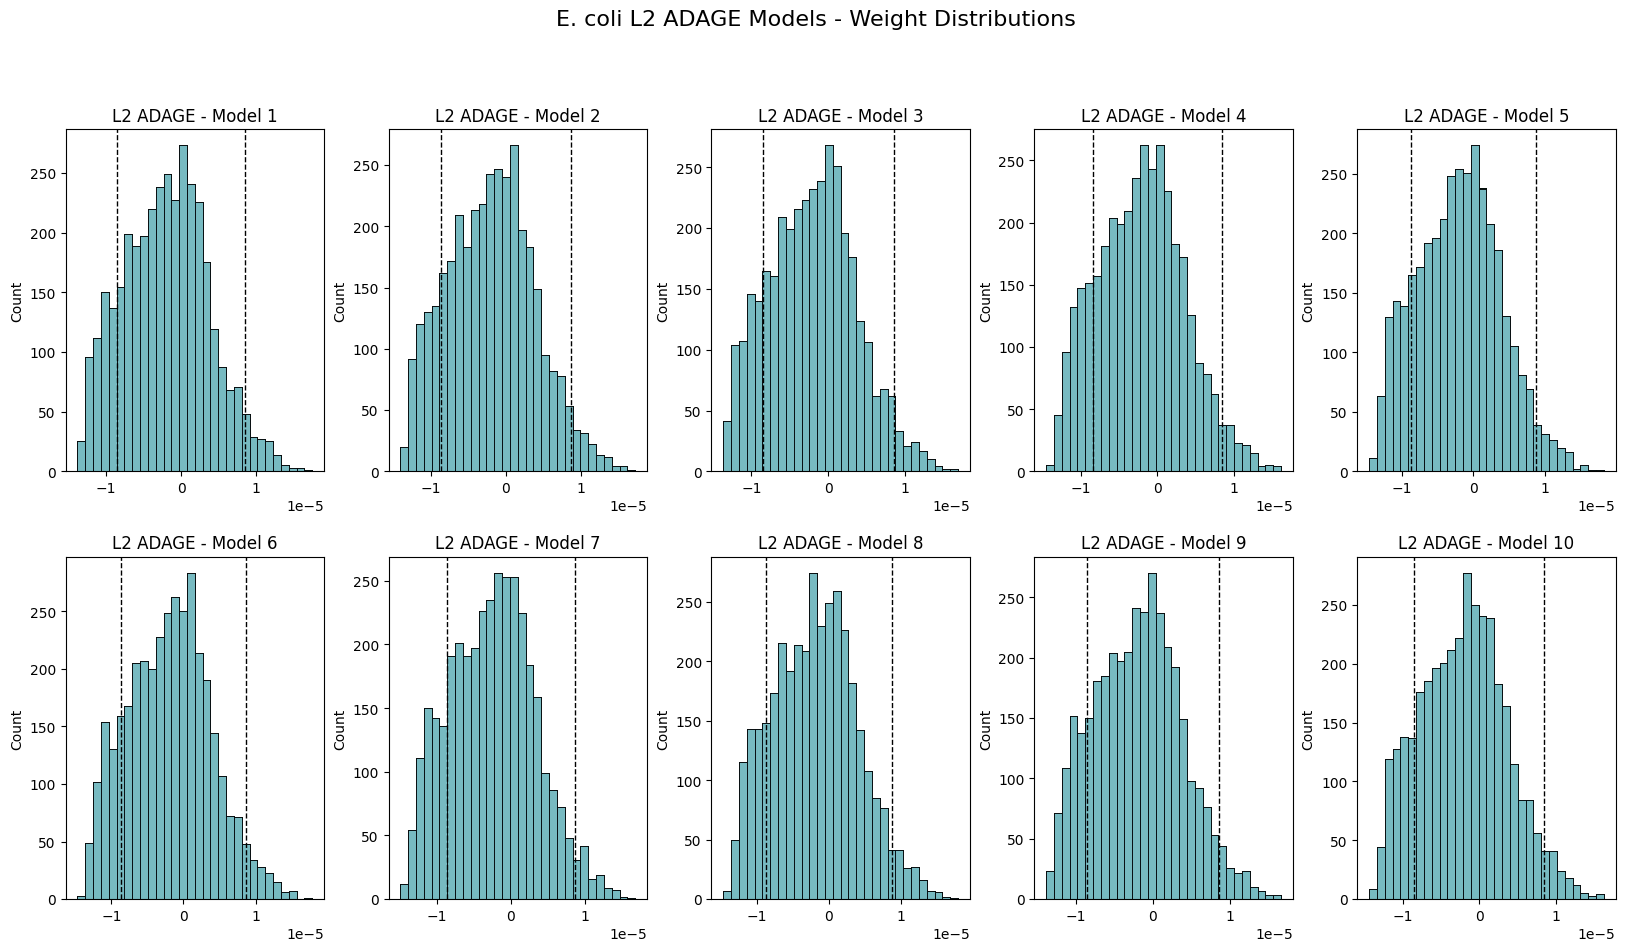

In [29]:
plot_titles = [
  f'L2 ADAGE - Model {i+1}'
  for i in range(10)
]
fig, ax = plt.subplots(2, 5, figsize = (20, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli L2 ADAGE Models - Weight Distributions',
  fontsize = 16,
  y = 1
)
colorblind_colors = sns.color_palette("colorblind")

for i in range(2):
  for j in range(5):
    weights_matrix = np.asarray(loaded_models[5*i + j].autoencoder.get_weights()[0])

    for node in range(optimal_hps['units']):
      weights = weights_matrix[:, node]
      weights = weights[np.isfinite(weights)]

      # Skip empty arrays and constant distributions
      if len(weights) == 0 or np.min(weights) == np.max(weights):
        continue

      # Each hidden node weight distribution
      sns.histplot(
        weights,
        ax = ax[i, j],
        color = colorblind_colors[node % len(colorblind_colors)],
        bins = 30,
        kde = False,
        zorder = 0
      )

    all_weights = weights_matrix.flatten()
    all_weights = all_weights[np.isfinite(all_weights)]
    cutoff = np.std(all_weights) * 1.5

    ax[i, j].axvline(
        x = cutoff,
        color = 'black',
        linestyle = '--',
        linewidth = 1
    )
    ax[i, j].axvline(
        x = -cutoff,
        color = 'black',
        linestyle = '--',
        linewidth = 1
    )
    ax[i, j].set(title = plot_titles[5*i + j])

fig.savefig(
  '/content/drive/MyDrive/Mukundan - Senior Project/L2 Models/Plots/ec_l2_weight_dists.png',
  dpi = 300,
  bbox_inches = 'tight'
)

### 2e. Perform KEGG analysis

In [31]:
# Load KEGG p-value matrices
kegg_ps = [
  pd.read_csv(
    f'/content/drive/My Drive/Mukundan - Senior Project/L2 Models/kegg_dfs/ec_L2_kegg_ps{i+1}.csv'
  )
  for i in range(75)
]

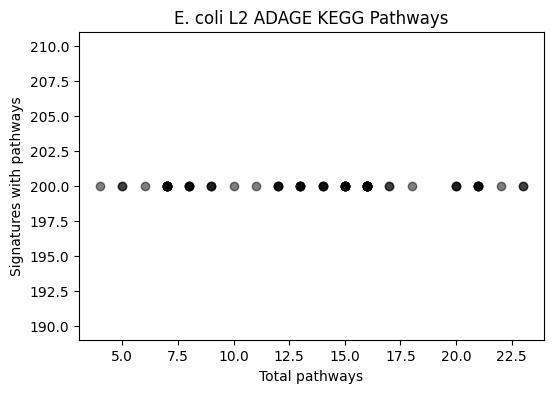

In [32]:
# Plot KEGG pathways
plt.figure(figsize = (6, 4))

for kegg_vals in kegg_ps:
  x = ((kegg_vals > 1.5).sum(0) > 0).sum()
  y = ((kegg_vals > 1.5).sum(1) > 0).sum()
  plt.scatter(x, y, alpha = 0.5, color = "black")

plt.title('E. coli L2 ADAGE KEGG Pathways')
plt.xlabel('Total pathways')
plt.ylabel('Signatures with pathways')

plt.savefig(
  '/content/drive/MyDrive/Mukundan - Senior Project/L2 Models/Plots/ec_l2_kegg.png',
  dpi = 300,
  bbox_inches = 'tight'
)